# CSCI 3151 — Foundations of Machine Learning  
### M20 — Support vector machines & margins

In this mini-lab, you will run and analyze **support vector machine (SVM)** classifiers on small 2D datasets.

We'll focus on two concrete questions:

- How does the **regularization parameter** $C$ affect the **margin**, number of **support vectors**, and performance for a (nearly) linearly separable problem?
- How do **$C$ and $\gamma$** interact in an **RBF-kernel SVM** on a nonlinear dataset like two noisy moons?

The goal is to treat SVMs as tools you can **poke and prod with code**: run small experiments, record results, and connect them back to the **margin intuition** from the video.
    
**This mini-lab reinforces…**

- Geometric and functional **margins** for linear SVMs.  
- The role of the **regularization parameter** $C$ in soft/hard margins.  
- How **RBF kernels** use $C$ and $\gamma$ to control decision boundary complexity.  
- Basic **experimental practice**: small hyperparameter sweeps, simple plots, and reading tables of results.


## Assumptions & scope

- You are comfortable with **Python**, **NumPy**, **pandas**, and basic plotting with **matplotlib**.
- You have seen linear classifiers (logistic regression / perceptron) and the **SVM margin idea** in the M20 video.
- We work with **small synthetic datasets** (`make_blobs`, `make_moons`) so we can clearly see the geometry.
- We will *not* derive the full optimization algorithms here — instead, we use scikit-learn's SVM implementations and focus on **coding experiments and interpretation**.
- Time is limited (~30 minutes): prioritize **Part 1** and **the first half of Part 2**. Any extra experiments you try are a bonus.


In [1]:
# Setup: imports, configuration, and random seed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs, make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import accuracy_score

# Reproducibility
SEED = 2151
np.random.seed(SEED)

# Matplotlib defaults
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = True

print("Setup complete.")


Setup complete.


In [2]:
# Helper functions
    
def plot_decision_boundary(clf, X, y, ax=None, h=0.02, title=None):
    """Plot the decision boundary for a fitted 2D classifier.
    
    Parameters
    ----------
    clf : fitted classifier with .predict
    X : array-like of shape (n_samples, 2)
    y : array-like of shape (n_samples,)
    """
    X = np.asarray(X)
    y = np.asarray(y)

    if X.shape[1] != 2:
        raise ValueError("X must have exactly 2 features for this plot.")

    if ax is None:
        ax = plt.gca()

    x_min, x_max = X[:, 0].min() - 1.0, X[:, 0].max() + 1.0
    y_min, y_max = X[:, 1].min() - 1.0, X[:, 1].max() + 1.0
    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, h),
        np.arange(y_min, y_max, h),
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = clf.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.2)
    ax.scatter(X[:, 0], X[:, 1], c=y, edgecolor="k", s=30)
    ax.set_xlabel("feature 1")
    ax.set_ylabel("feature 2")
    if title is not None:
        ax.set_title(title)
    return ax


def geometric_margin_from_linear_svc(clf, X, y):
    """Approximate geometric margin gamma = min_i y_i (w^T x_i + b) / ||w||.

    This only makes sense for a *linear* SVM; here we treat it as an
    approximate diagnostic even in the soft-margin case.
    """
    # LinearSVC stores coef_ and intercept_ directly; for SVC(kernel="linear")
    # we get a dense w by summing support vectors.
    if hasattr(clf, "coef_"):
        w = clf.coef_[0]
        b = clf.intercept_[0]
    else:
        raise ValueError("Classifier must expose coef_ and intercept_.")

    X = np.asarray(X)
    y_signed = np.where(y == 0, -1, 1)

    scores = y_signed * (X @ w + b)
    w_norm = np.linalg.norm(w)
    if w_norm == 0:
        return np.nan
    return scores.min() / w_norm


## Part 1 — Linear SVMs, margins, and the effect of C (core)

In this part, we'll use a **(mostly) linearly separable** 2D dataset and study how the
**regularization strength** `C` affects:

- the **geometric margin**,
- the **number of support vectors**, and
- training vs validation **accuracy**.

We'll work with a simple blob dataset and a **linear SVM** implemented via `LinearSVC`.


Train shape: (175, 2)  Val shape: (75, 2)


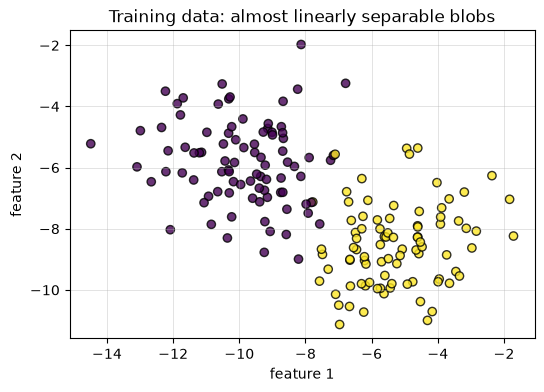

In [3]:
# Generate a (mostly) linearly separable dataset

X_blobs, y_blobs = make_blobs(
    n_samples=250,
    centers=2,
    cluster_std=1.4,
    random_state=SEED,
)

X_train, X_val, y_train, y_val = train_test_split(
    X_blobs, y_blobs,
    test_size=0.3,
    stratify=y_blobs,
    random_state=SEED,
)

print("Train shape:", X_train.shape, " Val shape:", X_val.shape)

plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, edgecolor="k", alpha=0.8)
plt.title("Training data: almost linearly separable blobs")
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.show()


### Core Task 1 — Sweep over C and inspect margins & support vectors

We'll scale the features and fit a **linear SVM** using `LinearSVC` inside a `Pipeline`.

1. Run the cell below as-is to try a few values of `C`.
2. Look at how **margin**, **number of support vectors**, and **accuracy** change.
3. If you have time, edit the `C_values` list (add smaller/larger values) and re-run.

*Hint:* larger `C` means we punish margin violations more heavily.


In [4]:
# Small sweep over C for a linear SVM

C_values = [0.1, 1.0, 10.0, 100.0]

rows = []

for C in C_values:
    # Linear SVM with scaling
    clf = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(C=C, random_state=SEED, dual="auto"))
    ])

    clf.fit(X_train, y_train)

    # Access the underlying LinearSVC to compute margin and support-like points
    base = clf.named_steps["svm"]
    # NOTE: LinearSVC does not expose support vectors directly.
    # We still compute an approximate geometric margin using coef_ and intercept_.
    gamma = geometric_margin_from_linear_svc(
        base,
        clf.named_steps["scaler"].transform(X_train),
        y_train,
    )

    y_train_pred = clf.predict(X_train)
    y_val_pred = clf.predict(X_val)

    train_acc = accuracy_score(y_train, y_train_pred)
    val_acc = accuracy_score(y_val, y_val_pred)

    rows.append({
        "C": C,
        "margin_gamma": gamma,
        "train_acc": train_acc,
        "val_acc": val_acc,
    })

results_linear = pd.DataFrame(rows).sort_values("C")
display(results_linear)


,C,margin_gamma,train_acc,val_acc
0,0.1,-0.189382,0.977143,0.986667
1,1.0,-0.144796,0.982857,0.986667
2,10.0,-0.139181,0.982857,0.986667
3,100.0,-0.131697,0.982857,0.986667


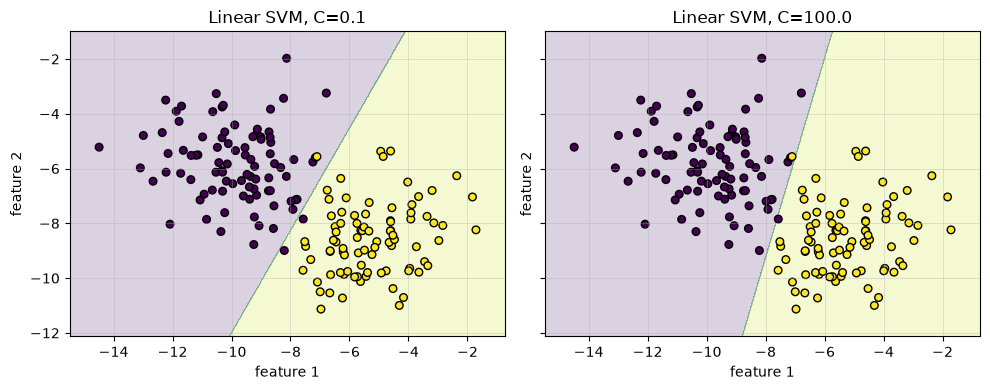

In [5]:
# Visualizing two extreme C values

C_small = 0.1
C_large = 100.0

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)

for C, ax, label in [
    (C_small, axes[0], f"Linear SVM, C={C_small}"),
    (C_large, axes[1], f"Linear SVM, C={C_large}"),
]:
    clf = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(C=C, random_state=SEED, dual="auto"))
    ])
    clf.fit(X_train, y_train)

    plot_decision_boundary(clf, X_train, y_train, ax=ax, title=label)

plt.tight_layout()
plt.show()


**Short reflection (jot down a few sentences):**

- As `C` increases, what happens to the **margin estimate** `margin_gamma`?
- How does this relate to the idea of **hard vs soft margins** from the M20 video?
- Do you see any sign of **overfitting** (very high train accuracy but worse validation accuracy) at large `C`?


## Part 2 — RBF-kernel SVMs on noisy moons (core / stretch)

Now we'll move to a **nonlinearly separable** dataset: two noisy half-moons.
Here, a straight line is not enough — we need a nonlinear decision boundary.

We'll use an **RBF-kernel SVM** and explore how **$C$ and $\gamma$** interact to
control the shape of the boundary.


Moons: train shape: (210, 2)  Val shape: (90, 2)


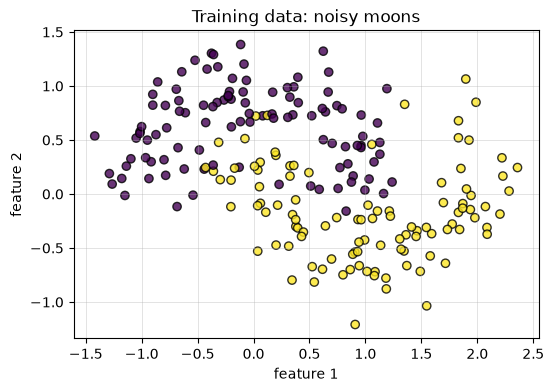

In [6]:
# Generate the noisy two-moons dataset

Xm, ym = make_moons(
    n_samples=300,
    noise=0.25,
    random_state=SEED,
)

Xm_train, Xm_val, ym_train, ym_val = train_test_split(
    Xm, ym,
    test_size=0.3,
    stratify=ym,
    random_state=SEED,
)

print("Moons: train shape:", Xm_train.shape, " Val shape:", Xm_val.shape)

plt.scatter(Xm_train[:, 0], Xm_train[:, 1], c=ym_train, edgecolor="k", alpha=0.8)
plt.title("Training data: noisy moons")
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.show()


### Core Task 2 — Small grid search over C and γ

We'll try a small grid of `(C, gamma)` values for an RBF SVM and collect:

- training and validation **accuracy**, and
- the total number of **support vectors**.

1. Run the code cell below as-is and inspect the resulting table.
2. Identify:
   - at least one **underfitting** setting (too smooth / low train acc),
   - at least one **overfitting** setting (train ≈ 1.0, val much worse),
   - and one **reasonable compromise**.
3. If you have time, edit the `C_values` / `gamma_values` lists and rerun.


In [7]:
# Small grid search for RBF SVM on noisy moons

C_values = [0.1, 1.0, 10.0]
gamma_values = [0.1, 1.0, 10.0]

rows = []

for C in C_values:
    for gamma in gamma_values:
        clf = Pipeline([
            ("scaler", StandardScaler()),
            ("svm", SVC(kernel="rbf", C=C, gamma=gamma, random_state=SEED))
        ])

        clf.fit(Xm_train, ym_train)

        y_train_pred = clf.predict(Xm_train)
        y_val_pred = clf.predict(Xm_val)

        train_acc = accuracy_score(ym_train, y_train_pred)
        val_acc = accuracy_score(ym_val, y_val_pred)

        # SVC exposes support_ indices directly
        base = clf.named_steps["svm"]
        n_support = base.support_.shape[0]

        rows.append({
            "C": C,
            "gamma": gamma,
            "train_acc": train_acc,
            "val_acc": val_acc,
            "n_support": n_support,
        })

results_rbf = pd.DataFrame(rows).sort_values(["val_acc", "train_acc"], ascending=False)
display(results_rbf)


,C,gamma,train_acc,val_acc,n_support
5,1.0,10.0,0.961905,0.922222,133
7,10.0,1.0,0.952381,0.922222,40
4,1.0,1.0,0.942857,0.922222,67
1,0.1,1.0,0.890476,0.900000,133
6,10.0,0.1,0.857143,0.900000,77
8,10.0,10.0,0.976190,0.877778,117
2,0.1,10.0,0.961905,0.877778,210
3,1.0,0.1,0.833333,0.844444,86
0,0.1,0.1,0.828571,0.844444,132


Chosen settings:
  Best-ish    : {'C': np.float64(1.0), 'gamma': np.float64(10.0), 'train_acc': np.float64(0.9619047619047619), 'val_acc': np.float64(0.9222222222222223), 'n_support': np.float64(133.0)}
  Overfitting?: {'C': np.float64(10.0), 'gamma': np.float64(10.0), 'train_acc': np.float64(0.9761904761904762), 'val_acc': np.float64(0.8777777777777778), 'n_support': np.float64(117.0)}


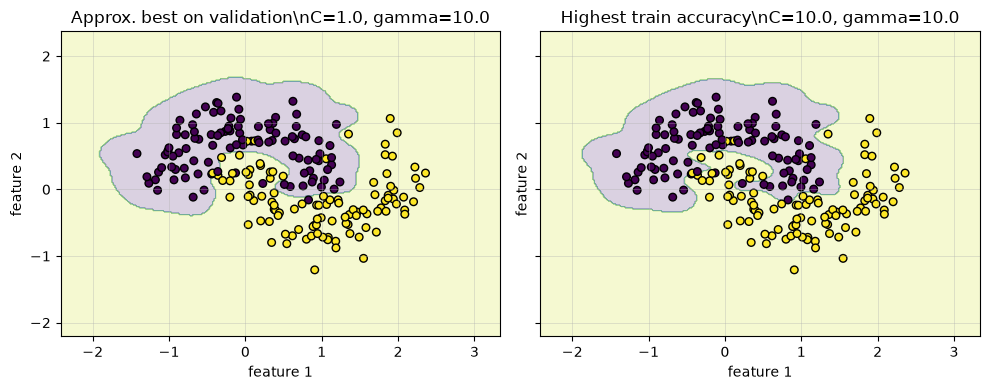

In [8]:
# Visualize a "good" and a "very wiggly" RBF SVM

# Best row by validation accuracy
best_row = results_rbf.iloc[0]

# Row with highest training accuracy (often overfitting)
overfit_row = results_rbf.sort_values("train_acc", ascending=False).iloc[0]

print("Chosen settings:")
print("  Best-ish    :", dict(best_row))
print("  Overfitting?:", dict(overfit_row))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)

for row, ax, label in [
    (best_row, axes[0], "Approx. best on validation"),
    (overfit_row, axes[1], "Highest train accuracy"),
]:
    C = row["C"]
    gamma = row["gamma"]

    clf = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=C, gamma=gamma, random_state=SEED))
    ])
    clf.fit(Xm_train, ym_train)

    plot_decision_boundary(
        clf,
        Xm_train,
        ym_train,
        ax=ax,
        title=f"{label}\\nC={C}, gamma={gamma}"
    )

plt.tight_layout()
plt.show()


**Quick analysis (write a few points):**

- For your underfitting setting, what do the `train_acc` and `val_acc` look like?
- For your overfitting setting, how does the decision boundary look compared to the data?
- How do your observations relate to the **bias–variance** intuition from earlier modules?


## (Optional stretch) Comparing linear vs RBF kernels on the same data

If you have extra time:

1. Fit a **linear SVM** (with scaling) on the noisy moons data.
2. Compare its performance and decision boundary to one of your best **RBF** models.
3. Summarize in 2–3 sentences when a **linear kernel** is clearly not enough.


Linear SVM train/val: 0.8333333333333334 0.8444444444444444
RBF SVM    train/val: 0.9619047619047619 0.9222222222222223


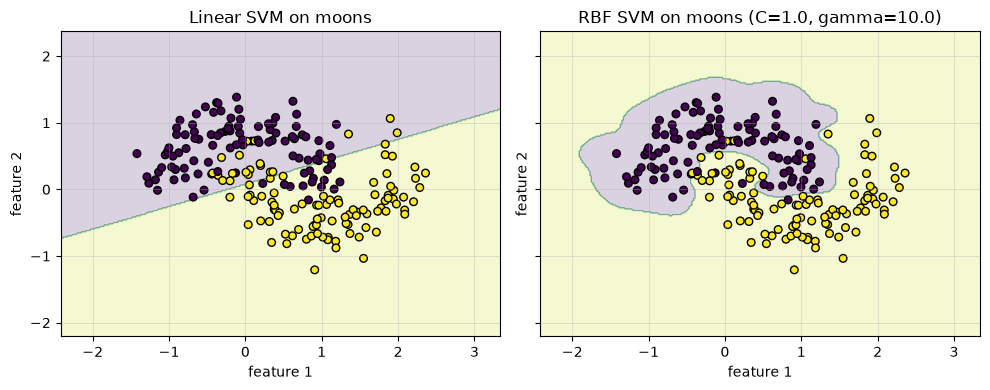

In [9]:
# Optional: linear vs RBF on the same noisy moons data

# Linear SVM (via LinearSVC)
linear_moons = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(C=1.0, random_state=SEED, dual="auto")),
])
linear_moons.fit(Xm_train, ym_train)

# Reuse the "best" RBF settings from above
best_C = results_rbf.iloc[0]["C"]
best_gamma = results_rbf.iloc[0]["gamma"]

rbf_moons = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=best_C, gamma=best_gamma, random_state=SEED)),
])
rbf_moons.fit(Xm_train, ym_train)

print("Linear SVM train/val:",
      accuracy_score(ym_train, linear_moons.predict(Xm_train)),
      accuracy_score(ym_val, linear_moons.predict(Xm_val)))
print("RBF SVM    train/val:",
      accuracy_score(ym_train, rbf_moons.predict(Xm_train)),
      accuracy_score(ym_val, rbf_moons.predict(Xm_val)))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)

plot_decision_boundary(
    linear_moons, Xm_train, ym_train, ax=axes[0], title="Linear SVM on moons"
)
plot_decision_boundary(
    rbf_moons, Xm_train, ym_train, ax=axes[1],
    title=f"RBF SVM on moons (C={best_C}, gamma={best_gamma})"
)

plt.tight_layout()
plt.show()
